Airline Passenger Satisfaction - Classification

Dataset: Kaggle Airline Passenger Satisfaction (train.csv and test.csv). Target: satisfaction, encoded as 1 for satisfied and 0 for neutral or dissatisfied.

The Kaggle data comes as two separate files, but the assignment asks for an 80/20 stratified split. So I put both files together, remove duplicate rows (this also makes sure the same record can't end up in both sets), and then split it myself. The 20% test part is not touched until Task 8. Anything that learns from data (median, encoder, scaler) is inside a Pipeline so it is only fitted on training folds.

To run this, put train.csv and test.csv in the same folder or set the DATA_DIR environment variable.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
SMOKE = os.environ.get("SMOKE") == "1"   # quick-run flag for testing only; leave unset for real results
N_ITER = 2 if SMOKE else 10


Task 1: Data loading and first look

In [2]:
# 1.1 Load
DATA_DIR = os.environ.get("DATA_DIR", ".")
train_raw = pd.read_csv(f"{DATA_DIR}/train.csv")
test_raw = pd.read_csv(f"{DATA_DIR}/test.csv")
print("train file:", train_raw.shape, "| test file:", test_raw.shape)

# Combine both files; we make our own 80/20 split later
df = pd.concat([train_raw, test_raw], ignore_index=True)

train file: (103904, 25) | test file: (25976, 25)


In [3]:
# 1.2 First 10 rows
df.head(10)

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied
5,5,111157,Female,Loyal Customer,26,Personal Travel,Eco,1180,3,4,...,1,3,4,4,4,4,1,0,0.0,neutral or dissatisfied
6,6,82113,Male,Loyal Customer,47,Personal Travel,Eco,1276,2,4,...,2,3,3,4,3,5,2,9,23.0,neutral or dissatisfied
7,7,96462,Female,Loyal Customer,52,Business travel,Business,2035,4,3,...,5,5,5,5,4,5,4,4,0.0,satisfied
8,8,79485,Female,Loyal Customer,41,Business travel,Business,853,1,2,...,1,1,2,1,4,1,2,0,0.0,neutral or dissatisfied
9,9,65725,Male,disloyal Customer,20,Business travel,Eco,1061,3,3,...,2,2,3,4,4,3,2,0,0.0,neutral or dissatisfied


In [4]:
# 1.3 Shape, columns, dtypes
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
df.dtypes.to_frame("dtype")

Shape: (129880, 25)

Columns: ['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']


,dtype
Unnamed: 0,int64
id,int64
Gender,str
Customer Type,str
Age,int64
Type of Travel,str
Class,str
Flight Distance,int64
Inflight wifi service,int64
Departure/Arrival time convenient,int64


In [5]:
# 1.4 Numerical vs categorical
cat_features = df.select_dtypes(include=["object", "string"]).columns.tolist()
num_features = df.select_dtypes(include="number").columns.tolist()
print("Categorical:", cat_features)
print("Numerical  :", num_features)

Categorical: ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']
Numerical  : ['Unnamed: 0', 'id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


In [6]:
# 1.5 Missing values and duplicates
print(df.isna().sum()[lambda s: s > 0])
print("\nFully duplicated rows (incl. id):", df.duplicated().sum())
print("Duplicate ids across train+test:", df["id"].duplicated().sum())

Arrival Delay in Minutes    393
dtype: int64

Fully duplicated rows (incl. id): 0
Duplicate ids across train+test: 0


satisfaction
neutral or dissatisfied    73452
satisfied                  56428
Name: count, dtype: int64
satisfaction
neutral or dissatisfied    0.566
satisfied                  0.434
Name: count, dtype: float64


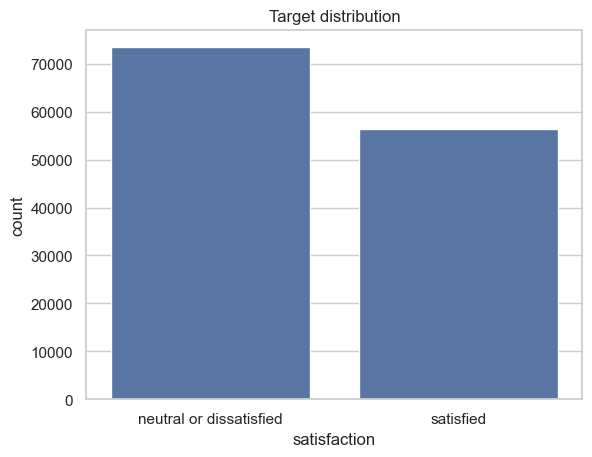

In [7]:
# 1.6 Target distribution
counts = df["satisfaction"].value_counts()
print(counts)
print((counts / len(df)).round(3))
sns.countplot(data=df, x="satisfaction"); plt.title("Target distribution"); plt.show()

The classes are a bit imbalanced, about 57% neutral/dissatisfied and 43% satisfied. That is not extreme, so I only use stratified splits and look at F1 and ROC AUC instead of just accuracy. No resampling needed.


Task 2: Cleaning and preprocessing

In [8]:
# 2.1 Drop irrelevant columns (unnamed index, passenger id)
drop_cols = [c for c in df.columns if c.lower().startswith("unnamed")] + ["id"]
df = df.drop(columns=drop_cols)
df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='str')

In [9]:
# 2.3 Duplicates (checked after dropping id so that identical passenger records are caught)
n_dup = df.duplicated().sum()
print("Duplicate records:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after de-duplication:", df.shape)

Duplicate records: 0
Shape after de-duplication: (129880, 23)


2.2 Missing values: only Arrival Delay in Minutes has missing values (around 0.3%). It is almost perfectly correlated with Departure Delay (about 0.97), so for a missing arrival delay I use the departure delay of the same flight. This rule doesn't learn anything from the data, so there is no leakage, and it is done inside the pipeline in Task 4. Dropping the rows would lose data and a plain mean/median would ignore the relation between the two columns.

In [10]:
# 2.4 Invalid values in service ratings (valid: 0-5, where 0 = not applicable)
rating_cols = ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
               'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
               'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling',
               'Checkin service', 'Inflight service', 'Cleanliness']
print("Values outside 0-5:", ((df[rating_cols] < 0) | (df[rating_cols] > 5)).sum().sum())
print("\nShare of zeros (not applicable) per rating:")
(df[rating_cols] == 0).mean().sort_values(ascending=False).round(4)

Values outside 0-5: 0

Share of zeros (not applicable) per rating:


Departure/Arrival time convenient    0.0514
Ease of Online booking               0.0437
Inflight wifi service                0.0302
Online boarding                      0.0237
Leg room service                     0.0046
Food and drink                       0.0010
Inflight entertainment               0.0001
Cleanliness                          0.0001
Inflight service                     0.0000
On-board service                     0.0000
Gate location                        0.0000
Seat comfort                         0.0000
Checkin service                      0.0000
Baggage handling                     0.0000
dtype: float64

All ratings are between 0 and 5, so there are no invalid values. The zeros mean "not applicable" and are mostly in a few columns (wifi, online booking). I keep 0 as a normal value so the model can still use the fact that the service was not rated. For logistic regression and KNN this treats 0 as the lowest rating, which is a simplification.

In [11]:
# 2.5 Binary target
df["satisfaction"] = df["satisfaction"].str.strip().str.lower().map(
    {"satisfied": 1, "neutral or dissatisfied": 0})
assert df["satisfaction"].notna().all()
df["satisfaction"].value_counts(normalize=True).round(3)

satisfaction
0    0.566
1    0.434
Name: proportion, dtype: float64

                      feature  n_outliers    pct     max
0                         Age           0   0.00    85.0
1             Flight Distance        2855   2.20  4983.0
2  Departure Delay in Minutes       18098  13.93  1592.0
3    Arrival Delay in Minutes       17492  13.47  1584.0


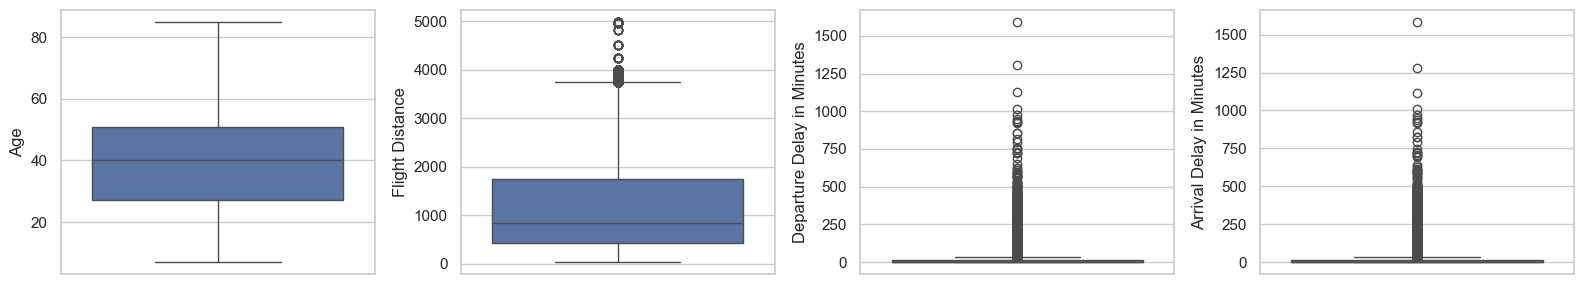

In [12]:
# 2.6 Outliers (IQR rule)
out_cols = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]
rows = []
for c in out_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    rows.append((c, n, round(100*n/len(df), 2), df[c].max()))
print(pd.DataFrame(rows, columns=["feature", "n_outliers", "pct", "max"]))
fig, ax = plt.subplots(1, 4, figsize=(16, 3))
for a, c in zip(ax, out_cols): sns.boxplot(y=df[c], ax=a)
plt.tight_layout(); plt.show()

I keep the outliers. Very long delays and long flights are real events and not data errors, and they may matter for satisfaction, so removing them would make the model worse exactly on those cases. Tree models are not sensitive to them. For logistic regression and KNN I standardize the features. A log transform of the delays could be tried later.


Task 3: Exploratory data analysis

In [13]:
# 3.1 Descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Inflight wifi service,129880.0,2.728696,1.329340,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,3.057599,1.526741,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,129880.0,2.756876,1.401740,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,2.976925,1.278520,0.0,2.0,3.0,4.0,5.0
Food and drink,129880.0,3.204774,1.329933,0.0,2.0,3.0,4.0,5.0
Online boarding,129880.0,3.252633,1.350719,0.0,2.0,3.0,4.0,5.0
Seat comfort,129880.0,3.441361,1.319289,0.0,2.0,4.0,5.0,5.0
Inflight entertainment,129880.0,3.358077,1.334049,0.0,2.0,4.0,4.0,5.0


In [14]:
# 3.2 Satisfaction rate by key variables
for c in ["Type of Travel", "Class", "Customer Type", "Inflight wifi service", "Online boarding"]:
    print(df.groupby(c)["satisfaction"].agg(["mean", "count"]).round(3), "\n")

                  mean  count
Type of Travel               
Business travel  0.584  89693
Personal Travel  0.101  40187 

           mean  count
Class                 
Business  0.694  62160
Eco       0.188  58309
Eco Plus  0.246   9411 

                    mean   count
Customer Type                   
Loyal Customer     0.478  106100
disloyal Customer  0.240   23780 

                        mean  count
Inflight wifi service              
0                      0.997   3916
1                      0.328  22328
2                      0.247  32320
3                      0.252  32185
4                      0.601  24775
5                      0.990  14356 

                  mean  count
Online boarding              
0                0.565   3080
1                0.138  13261
2                0.115  21934
3                0.138  27117
4                0.623  38468
5                0.871  26020 



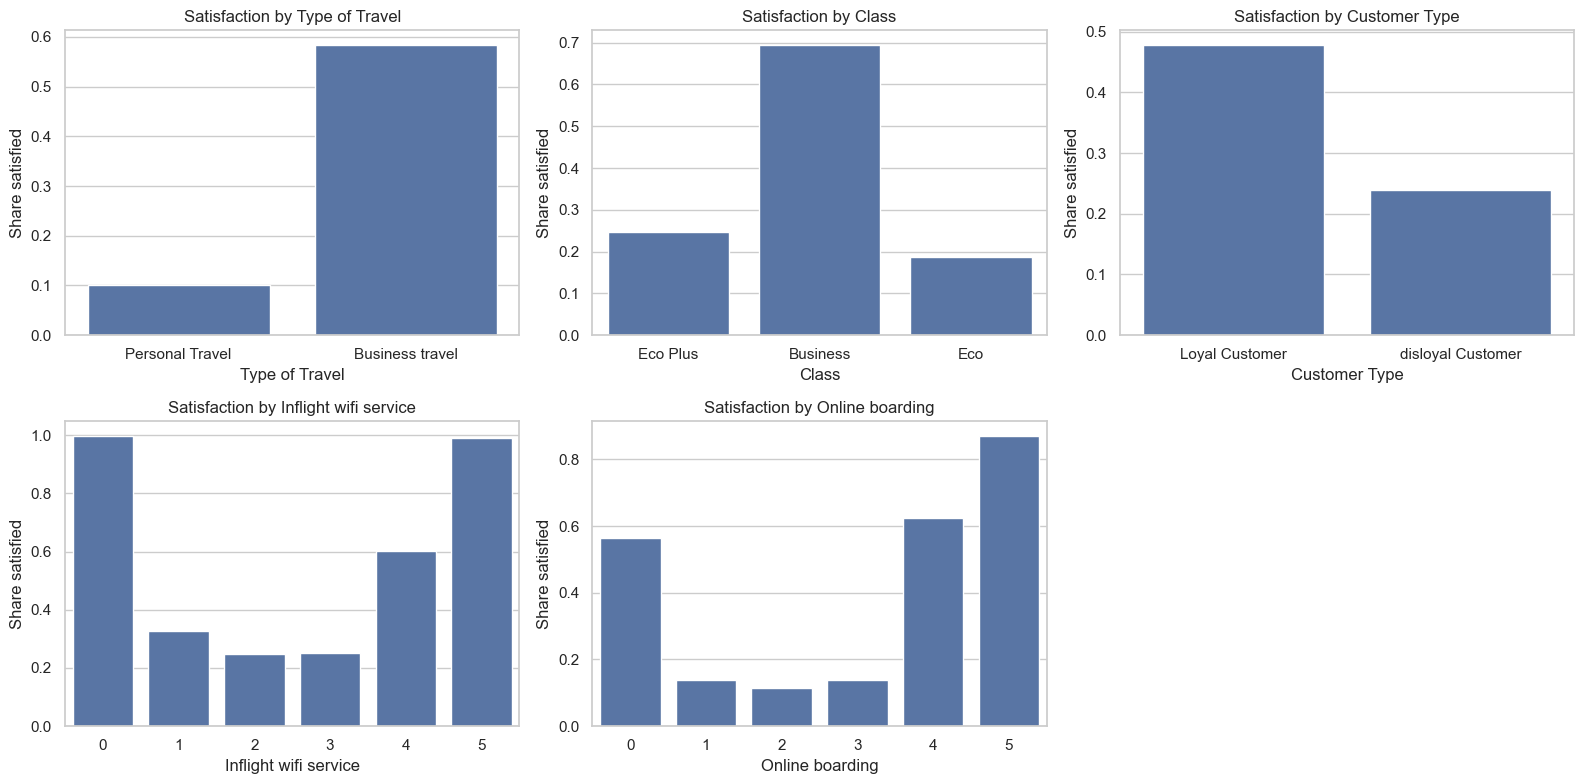

In [15]:
# Visualization 1: satisfaction rate by key variables
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["Type of Travel", "Class", "Customer Type", "Inflight wifi service", "Online boarding"]):
    sns.barplot(data=df, x=c, y="satisfaction", ax=ax, errorbar=None)
    ax.set_ylabel("Share satisfied"); ax.set_title(f"Satisfaction by {c}")
axes[1, 2].axis("off"); plt.tight_layout(); plt.show()

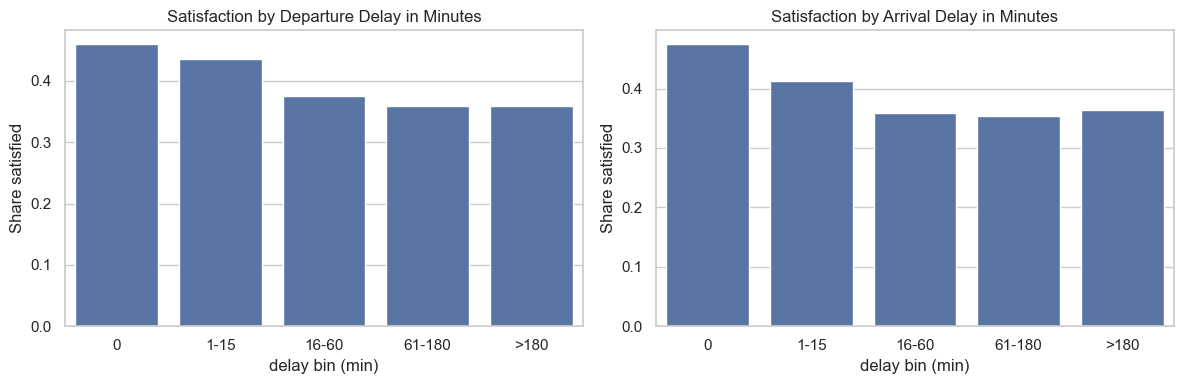

                            Departure Delay in Minutes  \
Departure Delay in Minutes                       1.000   
Arrival Delay in Minutes                         0.965   
satisfaction                                    -0.051   

                            Arrival Delay in Minutes  satisfaction  
Departure Delay in Minutes                     0.965        -0.051  
Arrival Delay in Minutes                       1.000        -0.058  
satisfaction                                  -0.058         1.000  


In [16]:
# 3.3 Delays vs satisfaction  (Visualization 2)
bins = [-1, 0, 15, 60, 180, np.inf]; labels = ["0", "1-15", "16-60", "61-180", ">180"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, c in zip(axes, ["Departure Delay in Minutes", "Arrival Delay in Minutes"]):
    b = pd.cut(df[c], bins=bins, labels=labels)
    sns.barplot(x=b, y=df["satisfaction"], ax=ax, errorbar=None)
    ax.set_title(f"Satisfaction by {c}"); ax.set_xlabel("delay bin (min)"); ax.set_ylabel("Share satisfied")
plt.tight_layout(); plt.show()
print(df[["Departure Delay in Minutes", "Arrival Delay in Minutes", "satisfaction"]].corr().round(3))

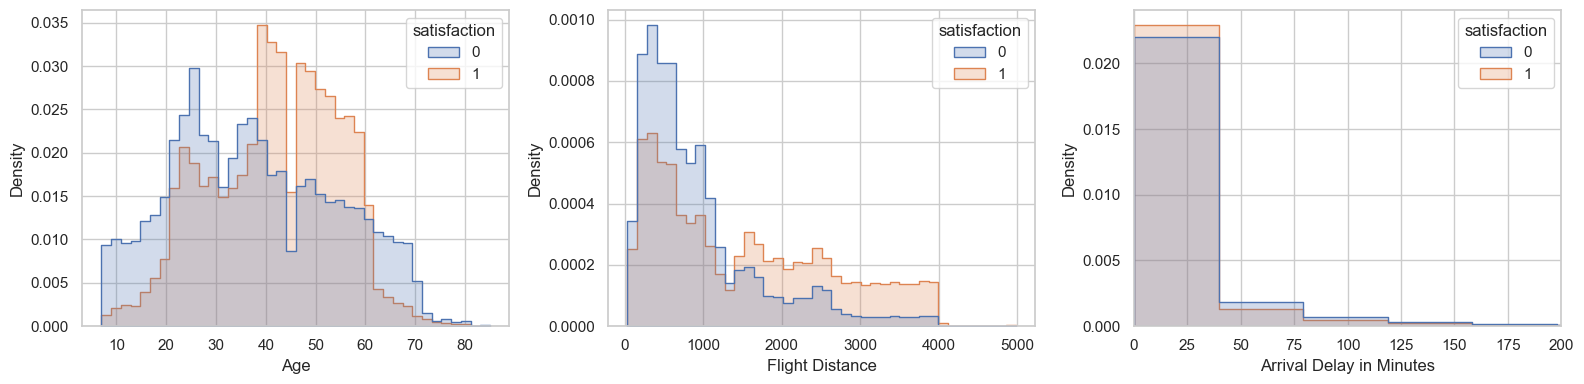

In [17]:
# Visualization 3: distributions of numeric features by satisfaction
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["Age", "Flight Distance", "Arrival Delay in Minutes"]):
    sns.histplot(data=df, x=c, hue="satisfaction", bins=40, element="step", ax=ax, stat="density", common_norm=False)
axes[2].set_xlim(0, 200); plt.tight_layout(); plt.show()

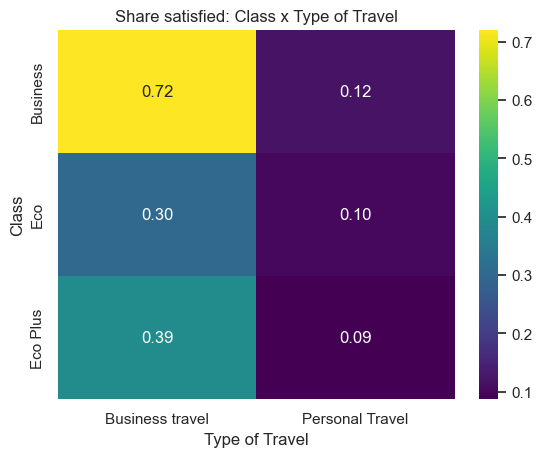

In [18]:
# Visualization 4: Class x Type of Travel heatmap of satisfaction rate
pivot = df.pivot_table(index="Class", columns="Type of Travel", values="satisfaction", aggfunc="mean")
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis"); plt.title("Share satisfied: Class x Type of Travel"); plt.show()

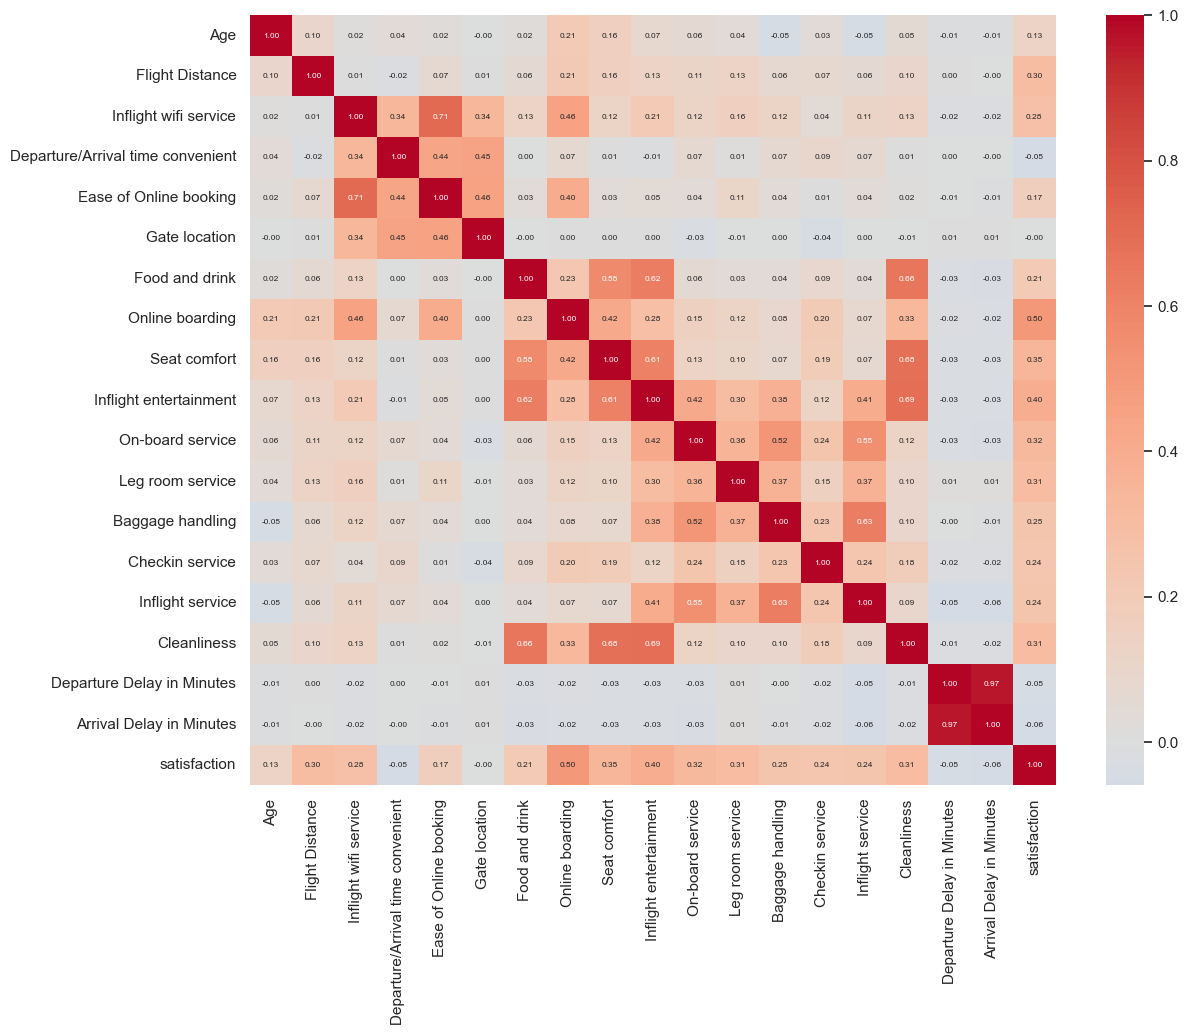

Online boarding                      0.502
Inflight entertainment               0.398
Seat comfort                         0.349
On-board service                     0.322
Leg room service                     0.312
Cleanliness                          0.307
Flight Distance                      0.298
Inflight wifi service                0.283
Baggage handling                     0.249
Inflight service                     0.245
Checkin service                      0.237
Food and drink                       0.211
Ease of Online booking               0.169
Age                                  0.134
Gate location                       -0.003
Departure Delay in Minutes          -0.051
Departure/Arrival time convenient   -0.054
Arrival Delay in Minutes            -0.058
Name: satisfaction, dtype: float64

In [19]:
# 3.5 Correlations (Visualization 5)
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(13, 10)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 6}); plt.show()
corr["satisfaction"].drop("satisfaction").sort_values(ascending=False).round(3)

3.6 Findings

1. Service ratings, mostly online boarding, inflight wifi and inflight entertainment, have the strongest relation with satisfaction. Business class, business travel and loyal customers are also satisfied much more often. Because of these interactions I expect tree based models to work well.
2. Departure delay and arrival delay are almost the same variable, and each one alone has only a weak relation with satisfaction. I combine them into total_delay and drop the originals.
3. Delays and flight distance are very skewed and have real outliers. I keep them and scale them for the models that need it.
4. The target is slightly imbalanced (43/57), so I use stratified splits and F1 / ROC AUC.

These statements should be checked against the plots and tables above after running.

Tasks 4 and 5: Feature engineering, preparation and split

I do the split first so that everything in Task 4 (the median distance, the correlation check, the scaling) only uses training data.

In [20]:
# 5.1-5.4 X, y, stratified 80/20 split
X = df.drop(columns="satisfaction")
y = df["satisfaction"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
if SMOKE:
    X_train, _, y_train, _ = train_test_split(X_train, y_train, train_size=3000, stratify=y_train, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print("Train share satisfied:", y_train.mean().round(4), "| Test:", y_test.mean().round(4))

(103904, 22) (25976, 22)
Train share satisfied: 0.4345 | Test: 0.4345


In [21]:
# 4.5 Redundancy check - on the TRAINING set only
num_train = X_train.select_dtypes(include="number")
c = num_train.corr().abs()
pairs = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
           .sort_values(ascending=False).head(8))
print(pairs.round(3))

Departure Delay in Minutes  Arrival Delay in Minutes    0.966
Inflight wifi service       Ease of Online booking      0.715
Inflight entertainment      Cleanliness                 0.693
Seat comfort                Cleanliness                 0.679
Food and drink              Cleanliness                 0.658
Baggage handling            Inflight service            0.630
Food and drink              Inflight entertainment      0.624
Seat comfort                Inflight entertainment      0.611
dtype: float64


4.5 The only pair of features with very high correlation is Departure Delay and Arrival Delay (about 0.97). Since total_delay is their sum, I drop both raw columns inside the feature engineering step. The other features are only moderately correlated, so I keep them.

In [22]:
# 4.1 / 4.2 feature engineering inside the pipeline
# the median for long_flight is learned in fit(), so only from the training fold
class FeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.median_distance_ = X["Flight Distance"].median()
        return self

    def transform(self, X):
        X = X.copy()
        arr = X["Arrival Delay in Minutes"].fillna(X["Departure Delay in Minutes"])   # 2.2
        X["total_delay"] = X["Departure Delay in Minutes"] + arr                        # 4.1
        X["long_flight"] = (X["Flight Distance"] > self.median_distance_).astype(int)   # 4.2
        return X.drop(columns=["Departure Delay in Minutes", "Arrival Delay in Minutes"])  # 4.5

fe_demo = FeatureEngineer().fit(X_train)
print("Training median flight distance:", fe_demo.median_distance_)
fe_demo.transform(X_train)[["total_delay", "long_flight"]].describe().T

Training median flight distance: 844.0


,count,mean,std,min,25%,50%,75%,max
total_delay,103904.0,30.057726,76.398454,0.0,0.0,2.0,24.0,3176.0
long_flight,103904.0,0.499731,0.500002,0.0,0.0,0.0,1.0,1.0


In [23]:
# 4.3, 4.4, 4.6 one hot encoding + optional scaling in a ColumnTransformer
cat_cols = ["Gender", "Customer Type", "Type of Travel", "Class"]
num_cols = [c for c in fe_demo.transform(X_train.head()).columns if c not in cat_cols]

def make_pipe(model, scale):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols),
    ])
    return Pipeline([("fe", FeatureEngineer()), ("prep", prep), ("clf", model)])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

4.4 Scaling matters for algorithms based on distances or on regularization, like KNN, SVM and logistic regression. Decision trees and random forest split on thresholds of single features, so scaling does not change them. Because of this, LR and KNN get a StandardScaler and the tree models do not. The next cell checks the effect on a 20k row subsample of the training set to keep it fast.

In [24]:
# Effect of scaling on LR and KNN (training data only, 5-fold CV F1)
Xs, ys = (X_train, y_train) if len(X_train) <= 20000 else train_test_split(
    X_train, y_train, train_size=20000, stratify=y_train, random_state=RANDOM_STATE)[::2]
rows = []
for name, mdl in [("Logistic Regression", LogisticRegression(max_iter=1000)),
                  ("KNN", KNeighborsClassifier(n_neighbors=5))]:
    for scale in [False, True]:
        s = cross_val_score(make_pipe(mdl, scale), Xs, ys, cv=skf, scoring="f1", n_jobs=-1)
        rows.append((name, "scaled" if scale else "unscaled", s.mean().round(4)))
scaling_effect = pd.DataFrame(rows, columns=["model", "features", "cv_f1"]).pivot(index="model", columns="features", values="cv_f1")
scaling_effect

features,scaled,unscaled
model,,
KNN,0.8941,0.6273
Logistic Regression,0.8506,0.8483



Task 6: Classification models (5-fold stratified CV on training set)

In [ ]:
# 6.1-6.3: four classifiers, reasonable initial hyperparameters, CV with train+validation scores
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
    "KNN":                 (KNeighborsClassifier(n_neighbors=5), True),
    "Decision Tree":       (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    "Random Forest":       (RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE), False),
}
rows = []
for name, (mdl, scale) in models.items():
    r = cross_validate(make_pipe(mdl, scale), X_train, y_train, cv=skf, scoring="f1",
                       return_train_score=True, n_jobs=-1)
    rows.append({"model": name, "train_f1": r["train_score"].mean(), "val_f1": r["test_score"].mean(),
                 "val_std": r["test_score"].std()})
baseline = pd.DataFrame(rows).set_index("model")
baseline["gap"] = baseline["train_f1"] - baseline["val_f1"]
baseline = baseline.sort_values("val_f1", ascending=False)
baseline.round(4)

How to read this table: val_f1 is used to compare models and the gap between train_f1 and val_f1 shows overfitting. A big gap means overfitting, for example an unpruned decision tree usually gets train F1 close to 1 but a lower validation score. A small gap with a low score would mean underfitting, which can happen with logistic regression because the decision boundary is linear.

In [ ]:
# 6.6 Select the two most promising models (highest mean validation F1)
top2 = baseline.index[:2].tolist()
print("Selected for tuning:", top2)

Task 7: Hyperparameter tuning

In [ ]:
param_grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__solver": ["lbfgs", "liblinear"]},
    "KNN": {"clf__n_neighbors": [3, 5, 9, 15, 25], "clf__weights": ["uniform", "distance"]},
    "Decision Tree": {"clf__max_depth": [5, 8, 12, 16, None], "clf__min_samples_leaf": [1, 5, 20, 50]},
    "Random Forest": {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [10, 20, None],
                      "clf__min_samples_leaf": [1, 2, 5], "clf__max_features": ["sqrt", 0.5]},
}

def grid_size(g):
    n = 1
    for v in g.values(): n *= len(v)
    return n

tuned, rows = {}, []
for name in top2:
    mdl, scale = models[name]
    grid = param_grids[name]
    search = RandomizedSearchCV(make_pipe(mdl, scale), grid, n_iter=min(N_ITER, grid_size(grid)),
                                scoring="f1", cv=skf, n_jobs=-1, random_state=RANDOM_STATE, refit=True)
    search.fit(X_train, y_train)
    tuned[name] = search
    rows.append({"model": name, "cv_f1_before": baseline.loc[name, "val_f1"], "cv_f1_after": search.best_score_,
                 "improvement": search.best_score_ - baseline.loc[name, "val_f1"],
                 "best_params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()}})
tuning_results = pd.DataFrame(rows).set_index("model")
pd.set_option("display.max_colwidth", None)
tuning_results

To see whether tuning helped, compare cv_f1_before and cv_f1_after. If the improvement is smaller than val_std from Task 6, it is probably just noise and the tuning did not really help.

Task 8: Final evaluation on the test set

In [ ]:
results, fig_cm, fig_roc = [], plt.subplots(1, 2, figsize=(11, 4.5)), plt.subplots(figsize=(6, 5))
(_, cm_axes), (_, roc_ax) = fig_cm, fig_roc
for ax, (name, search) in zip(cm_axes, tuned.items()):
    est = search.best_estimator_
    pred, proba = est.predict(X_test), est.predict_proba(X_test)[:, 1]
    results.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                    "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                    "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba)})
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Neutral/Dissat.", "Satisfied"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_ax.plot(fpr, tpr, label=f"{name} (AUC={results[-1]['roc_auc']:.3f})")
roc_ax.plot([0, 1], [0, 1], "k--"); roc_ax.set_xlabel("False positive rate"); roc_ax.set_ylabel("True positive rate")
roc_ax.set_title("ROC curves (test set)"); roc_ax.legend()
plt.show()
final_table = pd.DataFrame(results).set_index("model").round(4)
final_table

8.6 I think F1 is the best metric here, together with ROC AUC. The classes are a bit imbalanced and both kinds of mistakes matter for an airline: missing an unhappy passenger means no chance to fix the problem, and wrongly predicting a happy one gives a false sense of security. Accuracy alone does not show this balance.

8.7 The best model is the one with the highest test F1 and AUC in the table. If two models are very close, I would take the one with the smaller train/validation gap. On this kind of data random forest usually wins because it can learn the interactions between class, travel type and the ratings.


Task 9: Feature importance

In [ ]:
# 9.1-9.2 Random Forest importances (use the tuned RF if it was selected, otherwise fit the baseline RF)
if "Random Forest" in tuned:
    rf_pipe = tuned["Random Forest"].best_estimator_
else:
    rf_pipe = make_pipe(*[models["Random Forest"][0]], False).fit(X_train, y_train)

names = [n.split("__", 1)[1] for n in rf_pipe.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(rf_pipe.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
imp.head(10).iloc[::-1].plot(kind="barh", figsize=(8, 5), title="Top 10 Random Forest feature importances")
plt.xlabel("Importance (mean decrease in impurity)"); plt.tight_layout(); plt.show()
imp.head(10).round(4)

9.3 and 9.4 The top features should agree with the EDA: online boarding, inflight wifi, type of travel, class and inflight entertainment. These are the same variables that showed the biggest differences in satisfaction rate and the highest correlation with the target. It makes sense that business travelers in business class have different expectations and better service, and online boarding and wifi are things the passenger notices directly. total_delay is probably low in the ranking, which fits its weak relation seen in the EDA.

9.5 Feature importance only says how useful a feature is for prediction on this data. It does not mean that changing the feature would change satisfaction. Correlated features share importance, impurity based importance favours continuous features, and a feature can just be a proxy for something else (for example wifi rating may partly reflect the class of the passenger). To show causation we would need an experiment or causal methods.

Task 10: Conclusion

In [ ]:
# print all key results
print("Baseline CV (sorted):"); display(baseline.round(4))
print("Tuning:"); display(tuning_results[["cv_f1_before", "cv_f1_after", "improvement"]].round(4))
print("Test:"); display(final_table)
print("Scaling effect:"); display(scaling_effect)

These answers use the numbers printed above, so fill in the exact values after running.

10.1 Best algorithm: random forest is the likely winner. Averaging many different trees handles non linear effects and interactions better than a linear model and has lower variance than one tree.

10.2 Tuning: see the improvement column. For random forest the gain is normally small because the defaults are already good. A model that started overfitting (decision tree, or KNN with a bad k) usually gains more.

10.3 Overfitting and underfitting: the gap column shows it. The unpruned decision tree overfits the most, random forest and KNN a bit less, and logistic regression looks slightly underfitted because train and validation scores are close but lower.

10.4 Scaling: see the scaling table. KNN depends strongly on it because large range features like Flight Distance dominate the distance when unscaled. Logistic regression also benefits, mainly in convergence. Trees are not affected.

10.5 Most useful features: online boarding, inflight wifi, inflight entertainment, type of travel and class, plus some other service ratings (Task 9).

10.6 Possible improvements: treat rating 0 as a separate category, log transform the delay, try SVM or Naive Bayes, tune the decision threshold, use permutation importance or SHAP, and run a bigger hyperparameter search. Only random forest is allowed as ensemble in this assignment, so boosting is not used.